In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration des graphiques
sns.set_theme(style="whitegrid")

print("Les bibliothèques sont prêtes !")


Les bibliothèques sont prêtes !


In [2]:

import os

for dossier, sous_dossiers, fichiers in os.walk("/kaggle/input"):
    for fichier in fichiers:
        if fichier.endswith(".csv"):
            print(os.path.join(dossier, fichier))


/kaggle/input/datasets/arashnic/hr-analytics-job-change-of-data-scientists/sample_submission.csv
/kaggle/input/datasets/arashnic/hr-analytics-job-change-of-data-scientists/aug_test.csv
/kaggle/input/datasets/arashnic/hr-analytics-job-change-of-data-scientists/aug_train.csv


In [3]:

df = pd.read_csv("/kaggle/input/datasets/arashnic/hr-analytics-job-change-of-data-scientists/aug_train.csv")

print("Dataset chargé avec succès !")
print(df.shape)


Dataset chargé avec succès !
(19158, 14)


In [4]:

df.head()


,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5,NaN,NaN,never,83,0.0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,<1,NaN,Pvt Ltd,never,52,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,0.0


In [5]:

# Nombre de lignes et de colonnes
print("Dimensions :", df.shape)

# Noms des colonnes
print("\nColonnes :")
print(df.columns.tolist())

# Types des variables et valeurs non manquantes
df.info()


Dimensions : (19158, 14)

Colonnes :
['enrollee_id', 'city', 'city_development_index', 'gender', 'relevent_experience', 'enrolled_university', 'education_level', 'major_discipline', 'experience', 'company_size', 'company_type', 'last_new_job', 'training_hours', 'target']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19158 entries, 0 to 19157
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   enrollee_id             19158 non-null  int64  
 1   city                    19158 non-null  object 
 2   city_development_index  19158 non-null  float64
 3   gender                  14650 non-null  object 
 4   relevent_experience     19158 non-null  object 
 5   enrolled_university     18772 non-null  object 
 6   education_level         18698 non-null  object 
 7   major_discipline        16345 non-null  object 
 8   experience              19093 non-null  object 
 9   company_size            13220 n

In [6]:

df.describe()


,enrollee_id,city_development_index,training_hours,target
count,19158.000000,19158.000000,19158.000000,19158.000000
mean,16875.358179,0.828848,65.366896,0.249348
std,9616.292592,0.123362,60.058462,0.432647
min,1.000000,0.448000,1.000000,0.000000
25%,8554.250000,0.740000,23.000000,0.000000
50%,16982.500000,0.903000,47.000000,0.000000
75%,25169.750000,0.920000,88.000000,0.000000
max,33380.000000,0.949000,336.000000,1.000000


In [7]:

df.describe(include="all")


,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
count,19158.000000,19158,19158.000000,14650,19158,18772,18698,16345,19093,13220,13018,18735,19158.000000,19158.000000
unique,NaN,123,NaN,3,2,3,5,6,22,8,6,6,NaN,NaN
top,NaN,city_103,NaN,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,50-99,Pvt Ltd,1,NaN,NaN
freq,NaN,4355,NaN,13221,13792,13817,11598,14492,3286,3083,9817,8040,NaN,NaN
mean,16875.358179,NaN,0.828848,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,65.366896,0.249348
std,9616.292592,NaN,0.123362,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,60.058462,0.432647
min,1.000000,NaN,0.448000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,0.000000
25%,8554.250000,NaN,0.740000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.000000,0.000000
50%,16982.500000,NaN,0.903000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,47.000000,0.000000
75%,25169.750000,NaN,0.920000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,88.000000,0.000000


In [8]:

# Nombre de valeurs manquantes par colonne
missing = df.isnull().sum().sort_values(ascending=False)

print(missing)


company_type              6140
company_size              5938
gender                    4508
major_discipline          2813
education_level            460
last_new_job               423
enrolled_university        386
experience                  65
enrollee_id                  0
city                         0
relevent_experience          0
city_development_index       0
training_hours               0
target                       0
dtype: int64


In [9]:

missing_percent = (df.isnull().mean() * 100).sort_values(
    ascending=False
)

print(missing_percent.round(2))


company_type              32.05
company_size              30.99
gender                    23.53
major_discipline          14.68
education_level            2.40
last_new_job               2.21
enrolled_university        2.01
experience                 0.34
enrollee_id                0.00
city                       0.00
relevent_experience        0.00
city_development_index     0.00
training_hours             0.00
target                     0.00
dtype: float64


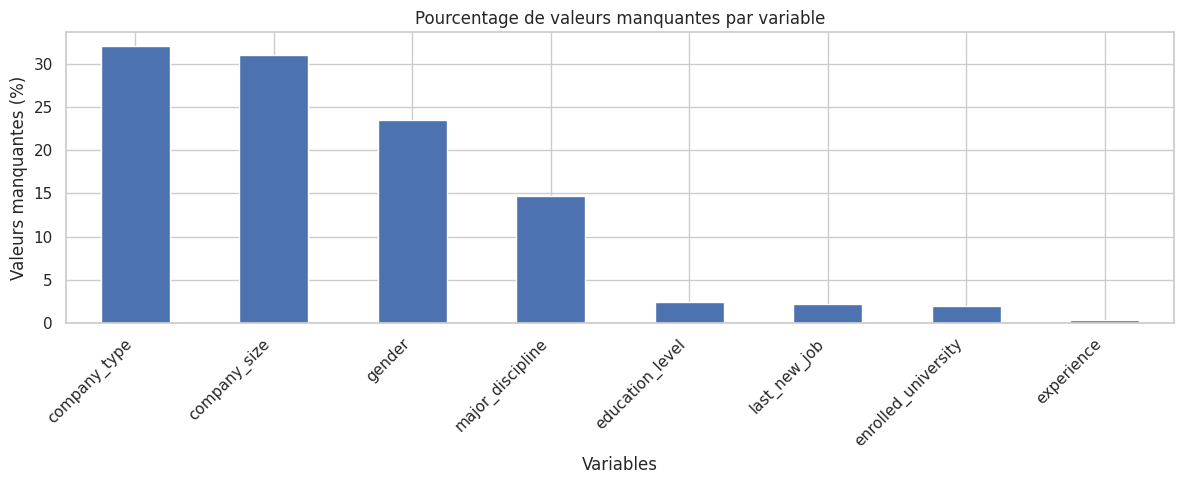

In [10]:

plt.figure(figsize=(12, 5))

missing_percent[missing_percent > 0].plot(kind="bar")

plt.title("Pourcentage de valeurs manquantes par variable")
plt.ylabel("Valeurs manquantes (%)")
plt.xlabel("Variables")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [11]:

print(df["target"].value_counts())

print("\nPourcentages :")
print(
    (df["target"].value_counts(normalize=True) * 100).round(2)
)


target
0.0    14381
1.0     4777
Name: count, dtype: int64

Pourcentages :
target
0.0    75.07
1.0    24.93
Name: proportion, dtype: float64


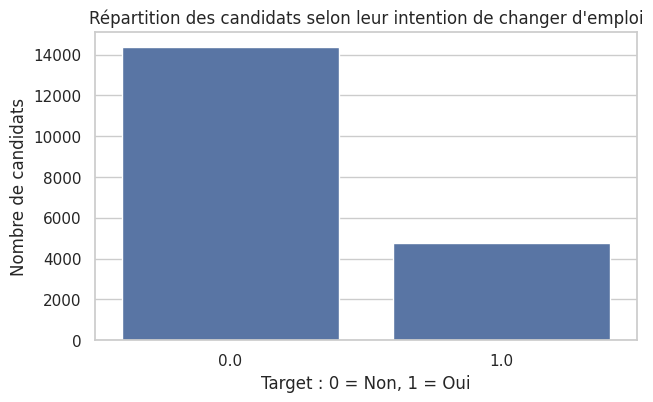

In [12]:

plt.figure(figsize=(7, 4))

sns.countplot(data=df, x="target")

plt.title("Répartition des candidats selon leur intention de changer d'emploi")
plt.xlabel("Target : 0 = Non, 1 = Oui")
plt.ylabel("Nombre de candidats")

plt.show()


In [13]:

missing = pd.DataFrame({
    "Valeurs_manquantes": df.isnull().sum(),
    "Pourcentage": df.isnull().mean() * 100
})

missing = missing.sort_values(
    by="Pourcentage",
    ascending=False
)

print(missing.round(2))


                        Valeurs_manquantes  Pourcentage
company_type                          6140        32.05
company_size                          5938        30.99
gender                                4508        23.53
major_discipline                      2813        14.68
education_level                        460         2.40
last_new_job                           423         2.21
enrolled_university                    386         2.01
experience                              65         0.34
enrollee_id                              0         0.00
city                                     0         0.00
relevent_experience                      0         0.00
city_development_index                   0         0.00
training_hours                           0         0.00
target                                   0         0.00


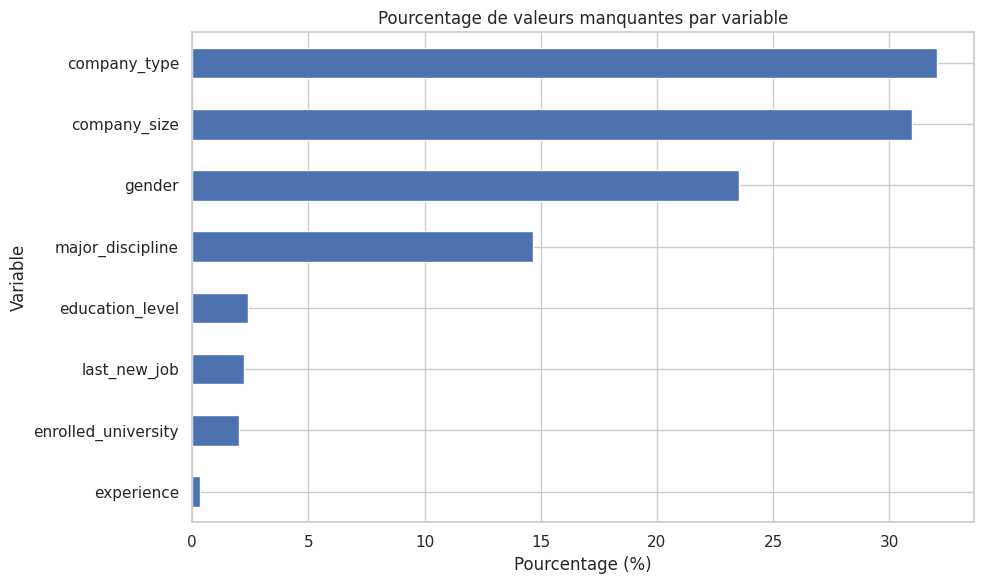

In [14]:

missing_pct = df.isnull().mean() * 100
missing_pct = missing_pct[missing_pct > 0].sort_values()

plt.figure(figsize=(10, 6))

missing_pct.plot(kind="barh")

plt.title("Pourcentage de valeurs manquantes par variable")
plt.xlabel("Pourcentage (%)")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()


In [15]:

print("Nombre de lignes dupliquées :", df.duplicated().sum())

print(
    "Nombre d'identifiants dupliqués :",
    df["enrollee_id"].duplicated().sum()
)


Nombre de lignes dupliquées : 0
Nombre d'identifiants dupliqués : 0


In [16]:

colonnes_categorielles = [
    "gender",
    "relevent_experience",
    "enrolled_university",
    "education_level",
    "major_discipline",
    "experience",
    "company_size",
    "company_type",
    "last_new_job"
]

for col in colonnes_categorielles:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))



--- gender ---
gender
Male      13221
NaN        4508
Female     1238
Other       191
Name: count, dtype: int64

--- relevent_experience ---
relevent_experience
Has relevent experience    13792
No relevent experience      5366
Name: count, dtype: int64

--- enrolled_university ---
enrolled_university
no_enrollment       13817
Full time course     3757
Part time course     1198
NaN                   386
Name: count, dtype: int64

--- education_level ---
education_level
Graduate          11598
Masters            4361
High School        2017
NaN                 460
Phd                 414
Primary School      308
Name: count, dtype: int64

--- major_discipline ---
major_discipline
STEM               14492
NaN                 2813
Humanities           669
Other                381
Business Degree      327
Arts                 253
No Major             223
Name: count, dtype: int64

--- experience ---
experience
>20    3286
5      1430
4      1403
3      1354
6      1216
2      1127
7      10

In [17]:

# Conserver le dataset original
df_clean = df.copy()

print("Dataset original :", df.shape)
print("Copie de travail :", df_clean.shape)


Dataset original : (19158, 14)
Copie de travail : (19158, 14)


In [18]:

# Colonnes catégorielles à traiter
colonnes_categorielles = [
    "gender",
    "enrolled_university",
    "education_level",
    "major_discipline",
    "experience",
    "company_size",
    "company_type",
    "last_new_job"
]

# Remplacer les valeurs manquantes par "Unknown"
for col in colonnes_categorielles:
    df_clean[col] = df_clean[col].fillna("Unknown")

# Vérifier les valeurs manquantes restantes
print(df_clean.isnull().sum().sort_values(ascending=False))


enrollee_id               0
city                      0
city_development_index    0
gender                    0
relevent_experience       0
enrolled_university       0
education_level           0
major_discipline          0
experience                0
company_size              0
company_type              0
last_new_job              0
training_hours            0
target                    0
dtype: int64


In [19]:

# Uniformiser le format de la taille des entreprises
df_clean["company_size"] = df_clean["company_size"].replace({
    "10/49": "10-49"
})

# Vérifier les catégories après correction
print(df_clean["company_size"].value_counts(dropna=False))


company_size
Unknown      5938
50-99        3083
100-500      2571
10000+       2019
10-49        1471
1000-4999    1328
<10          1308
500-999       877
5000-9999     563
Name: count, dtype: int64


In [20]:

# Rechercher les lignes entièrement dupliquées
print("Doublons complets :", df_clean.duplicated().sum())

# Vérifier les identifiants répétés
print(
    "Identifiants répétés :",
    df_clean["enrollee_id"].duplicated().sum()
)


Doublons complets : 0
Identifiants répétés : 0


In [22]:

df_clean = df_clean.drop_duplicates()

print("Dimensions après vérification :", df_clean.shape)


Dimensions après vérification : (19158, 14)


In [23]:

print(df_clean.dtypes)

print("\nValeurs de experience :")
print(df_clean["experience"].value_counts(dropna=False))

print("\nValeurs de target :")
print(df_clean["target"].value_counts(dropna=False))


enrollee_id                 int64
city                       object
city_development_index    float64
gender                     object
relevent_experience        object
enrolled_university        object
education_level            object
major_discipline           object
experience                 object
company_size               object
company_type               object
last_new_job               object
training_hours              int64
target                    float64
dtype: object

Valeurs de experience :
experience
>20        3286
5          1430
4          1403
3          1354
6          1216
2          1127
7          1028
10          985
9           980
8           802
15          686
11          664
14          586
1           549
<1          522
16          508
12          494
13          399
17          342
19          304
18          280
20          148
Unknown      65
Name: count, dtype: int64

Valeurs de target :
target
0.0    14381
1.0     4777
Name: count, dtype: int64


In [24]:

print("Dimensions finales :", df_clean.shape)

print("\nValeurs manquantes restantes :")
print(df_clean.isnull().sum())

print("\nDoublons complets restants :")
print(df_clean.duplicated().sum())

print("\nAperçu des données nettoyées :")
display(df_clean.head())


Dimensions finales : (19158, 14)

Valeurs manquantes restantes :
enrollee_id               0
city                      0
city_development_index    0
gender                    0
relevent_experience       0
enrolled_university       0
education_level           0
major_discipline          0
experience                0
company_size              0
company_type              0
last_new_job              0
training_hours            0
target                    0
dtype: int64

Doublons complets restants :
0

Aperçu des données nettoyées :


,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,Unknown,Unknown,1,36,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0.0
2,11561,city_21,0.624,Unknown,No relevent experience,Full time course,Graduate,STEM,5,Unknown,Unknown,never,83,0.0
3,33241,city_115,0.789,Unknown,No relevent experience,Unknown,Graduate,Business Degree,<1,Unknown,Pvt Ltd,never,52,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,0.0
